# Sieci neuronowe – ćwiczenie 2
## Regresja logistyczna uczona spadkiem gradientu · zbiór Heart Disease (Cleveland)

**Imię i nazwisko:** ……………… &nbsp;&nbsp; **Nr albumu:** ……………… &nbsp;&nbsp; **Termin zajęć:** ………………

> Kod przygotowany z pomocą narzędzia AI (Claude), oznaczony zgodnie z pkt 11 regulaminu.

---

### Najważniejsze wyniki

| | |
|---|---|
| minimum funkcji kosztu (zbiór treningowy) | $L^* = 0{,}287$ (start: $\ln 2 = 0{,}693$) |
| model bazowy (α = 0,1, wagi zerowe) | zbieżny po **1067** epokach, test: **F1 = 0,786**, accuracy 0,803 |
| współczynnik uczenia | α = 0,1 / 1 / 5 → 1067 / 106 / 18 epok; **α ≥ 20 nie zbiega** |
| inicjalizacja | małe wagi → to samo minimum; duże wagi → uczenie wielokrotnie dłuższe |
| warunek stopu | najlepszy koszt walidacyjny ok. **133. epoki**; early stopping i $\lvert\Delta L\rvert < 10^{-4}$ kończą po ok. 150 epokach |
| brak standaryzacji | uwarunkowanie 46 → 5,5 mln, F1 spada do ok. 0,65 |

**Spis treści:** 1. Cel · 2. Model i implementacja · 3. Model bazowy · 4. Współczynnik uczenia · 5. Inicjalizacja wag · 6. Liczba epok i warunek stopu · 7. Brak standaryzacji · 8. Odpowiedź na pytanie badawcze · 9. Wnioski

## 1. Cel ćwiczenia

Implementacja regresji logistycznej, czyli najprostszej (jednowarstwowej) sieci neuronowej, uczonej spadkiem gradientu na zbiorze Heart Disease. Badam:

- jakość klasyfikacji: **precision, recall, F1**,
- szybkość zbieżności w zależności od **współczynnika uczenia α**, **rozkładu inicjalizacji wag** oraz **liczby epok / warunku stopu** (krzywe uczenia).

**Pytanie badawcze:** czy klasyfikator liniowy zawsze zbiega do globalnego minimum? Czy zła parametryzacja uniemożliwia zbieżność i dobry wynik, czy tylko wydłuża uczenie?

## 2. Model i implementacja

### 2.1. Model

| element | wzór | znaczenie |
|---|---|---|
| wyjście | $p(x) = \sigma(Wx + b)$, $\;\sigma(z) = \dfrac{1}{1+e^{-z}}$ | prawdopodobieństwo choroby; klasa 1, gdy $p \ge 0{,}5$ |
| koszt (entropia krzyżowa) | $L = -\frac{1}{N}\sum \left[y \ln p + (1-y)\ln(1-p)\right]$ | średnia kara za błędne przewidywania |
| gradient | $\dfrac{\partial L}{\partial w_i} = -\frac{1}{N}\sum (y-p)\,x_i$, $\;\dfrac{\partial L}{\partial b} = -\frac{1}{N}\sum (y-p)$ | kierunek najszybszego wzrostu kosztu |
| krok | $w \leftarrow w - \alpha \dfrac{\partial L}{\partial w}$ | pełny batch: jedna epoka = jeden krok |

Funkcja kosztu jest **wypukła**: ma jedno minimum globalne i nie ma minimów lokalnych. Dlatego przy poprawnym uczeniu każdy start powinien doprowadzić do tego samego punktu $L^*$.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd())
from data import load_splits          # przygotowanie danych z ćw. 1

SEED = 42
pd.set_option("display.precision", 4)

# wspólny styl wykresów
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (12, 4), "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold",
    "legend.frameon": False,
})
C = {"train": "#1f5f8b", "val": "#e07b39", "ref": "#808080", "pos": "#2a7ab0", "neg": "#c8553d",
     "f1": "#1f5f8b", "precision": "#3a9d5d", "recall": "#b0478a"}

def rys(fig, nr, tytul):
    fig.suptitle(f"Rys. {nr}. {tytul}", fontsize=12, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

### 2.2. Implementacja (NumPy, bez gotowych metod uczenia)

In [2]:
def sigmoid(z):
    # wersja stabilna numerycznie: brak przepełnienia exp dla dużych |z|
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(float)
    tp = np.sum((yhat == 1) & (y == 1)); fp = np.sum((yhat == 1) & (y == 0))
    fn = np.sum((yhat == 0) & (y == 1)); tn = np.sum((yhat == 0) & (y == 0))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(precision=prec, recall=rec, f1=f1, accuracy=(tp + tn) / len(y))

def init_params(d, kind="zeros", scale=0.01, rng=None):
    rng = rng or np.random.default_rng(SEED)
    if kind == "zeros":     w = np.zeros(d)
    elif kind == "normal":  w = rng.normal(0.0, scale, d)
    elif kind == "uniform": w = rng.uniform(-scale, scale, d)
    elif kind == "const":   w = np.full(d, scale)
    return w, 0.0

In [3]:
class LogisticRegressionGD:
    # stop: None = stała liczba epok, "tol" = |L_t - L_(t-1)| < tol, "early" = early stopping na koszcie walidacyjnym
    def __init__(self, lr=0.1, epochs=1000, init="zeros", init_scale=0.01,
                 stop=None, tol=1e-6, patience=50, seed=SEED):
        self.lr, self.epochs, self.init, self.init_scale = lr, epochs, init, init_scale
        self.stop, self.tol, self.patience = stop, tol, patience
        self.rng = np.random.default_rng(seed)

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

    def fit(self, X, y, Xv=None, yv=None):
        self.w, self.b = init_params(X.shape[1], self.init, self.init_scale, self.rng)
        N = len(y)
        h = {k: [] for k in ["loss", "val_loss", "f1", "val_f1", "val_precision", "val_recall", "grad_norm"]}
        best = (np.inf, None, None, 0)
        self.stopped_at = self.epochs
        for ep in range(self.epochs):
            p = self.predict_proba(X)
            err = y - p
            gw = -(X.T @ err) / N               # dL/dw
            gb = -np.mean(err)                  # dL/db
            h["loss"].append(bce(y, p)); h["f1"].append(metrics(y, p)["f1"])
            h["grad_norm"].append(float(np.sqrt(gw @ gw + gb * gb)))
            if Xv is not None:
                pv = self.predict_proba(Xv); mv = metrics(yv, pv)
                h["val_loss"].append(bce(yv, pv)); h["val_f1"].append(mv["f1"])
                h["val_precision"].append(mv["precision"]); h["val_recall"].append(mv["recall"])
            if self.stop == "tol" and ep > 0 and abs(h["loss"][-2] - h["loss"][-1]) < self.tol:
                self.stopped_at = ep; break
            if self.stop == "early":
                if h["val_loss"][-1] < best[0] - 1e-9:
                    best = (h["val_loss"][-1], self.w.copy(), self.b, ep)
                elif ep - best[3] >= self.patience:
                    self.w, self.b = best[1], best[2]          # przywrócenie najlepszych wag
                    self.stopped_at, self.best_epoch = ep, best[3]; break
            self.w -= self.lr * gw                             # krok gradientowy
            self.b -= self.lr * gb
        self.history = h
        return self

def epochs_to(loss_hist, target):
    # pierwsza epoka, w której koszt spadł do poziomu target (None, jeśli nigdy)
    idx = np.where(np.asarray(loss_hist) <= target)[0]
    return int(idx[0]) if len(idx) else None

### 2.3. Dane

Przygotowanie z ćw. 1 (`data.py`): braki uzupełnione dominantą, cechy kategoryczne zakodowane one-hot, standaryzacja parametrami ze zbioru treningowego. Podział warstwowy 60/20/20.

In [4]:
(Xtr, ytr), (Xva, yva), (Xte, yte), names = load_splits(seed=SEED)
pd.DataFrame({"liczba pacjentów": [len(ytr), len(yva), len(yte)],
              "odsetek chorych": [ytr.mean(), yva.mean(), yte.mean()]},
             index=["treningowy", "walidacyjny", "testowy"]).round(3).assign(**{"liczba cech": Xtr.shape[1]})

,liczba pacjentów,odsetek chorych,liczba cech
treningowy,181,0.459,17
walidacyjny,61,0.459,17
testowy,61,0.459,17


### 2.4. Testy poprawności i minimum globalne

Zanim zacznę eksperymenty, sprawdzam, czy implementacja liczy dobrze:

- gradient ze wzoru porównuję z gradientem numerycznym $\frac{L(w+h) - L(w-h)}{2h}$,
- metryki porównuję ze scikit-learn,
- minimum $L^*$ wyznaczam bardzo długim treningiem i porównuję z `LogisticRegression` bez regularyzacji.

Za **zbieżność** przyjmuję $L \le L^* + 10^{-3}$.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# 1) gradient analityczny vs numeryczny
rng = np.random.default_rng(0)
X = rng.normal(size=(50, 4)); y = (rng.random(50) > 0.5).astype(float); w = rng.normal(size=4)
g_an = -(X.T @ (y - sigmoid(X @ w))) / len(y)
g_num = np.array([(bce(y, sigmoid(X @ (w + 1e-6 * e))) - bce(y, sigmoid(X @ (w - 1e-6 * e)))) / 2e-6 for e in np.eye(4)])

# 2) minimum globalne: długi trening + kontrola sklearn
ref = LogisticRegressionGD(lr=0.5, epochs=200_000, stop="tol", tol=1e-14).fit(Xtr, ytr)
L_star = ref.history["loss"][-1]
sk = LogisticRegression(C=np.inf, max_iter=100_000, tol=1e-12).fit(Xtr, ytr)
target = L_star + 1e-3

pd.DataFrame({"wynik": [
    f"{np.max(np.abs(g_an - g_num)):.1e}",
    "tak" if np.isfinite(sigmoid(np.array([-1000., 1000.]))).all() else "nie",
    "tak" if abs(metrics(ytr, ref.predict_proba(Xtr))["f1"] - f1_score(ytr, ref.predict_proba(Xtr) >= .5)) < 1e-12 else "nie",
    f"{L_star:.6f} (po {ref.stopped_at} epokach)",
    f"{abs(L_star - bce(ytr, sk.predict_proba(Xtr)[:, 1])):.1e}",
]}, index=["różnica gradientu (analityczny vs numeryczny)", "sigmoida bez NaN dla z = ±1000",
           "F1 zgodne ze sklearn", "minimum L*", "różnica kosztu vs sklearn"])

,wynik
różnica gradientu (analityczny vs numeryczny),1.4e-10
sigmoida bez NaN dla z = ±1000,tak
F1 zgodne ze sklearn,tak
minimum L*,0.287171 (po 2523 epokach)
różnica kosztu vs sklearn,1.1e-12


> **Wniosek:** gradient zgadza się z numerycznym do ok. $10^{-10}$, a koszt w minimum ze scikit-learn do $10^{-12}$. Implementacja jest poprawna, a $L^* = 0{,}2872$ to minimum globalne, do którego odnoszę zbieżność we wszystkich dalszych eksperymentach.

## 3. Model bazowy

Punkt odniesienia dla wszystkich eksperymentów: **α = 0,1, wagi zerowe, 2000 epok**, bez warunku stopu. Każdy kolejny eksperyment zmienia tylko jedną rzecz.

In [6]:
base = LogisticRegressionGD(lr=0.1, epochs=2000).fit(Xtr, ytr, Xva, yva)
h = base.history
print("epoki do zbieżności:", epochs_to(h["loss"], target))
pd.DataFrame({k: metrics(yy, base.predict_proba(XX)) for k, XX, yy in
              [("treningowy", Xtr, ytr), ("walidacyjny", Xva, yva), ("testowy", Xte, yte)]}).T.round(3)

epoki do zbieżności: 1067


,precision,recall,f1,accuracy
treningowy,0.919,0.819,0.866,0.884
walidacyjny,0.815,0.786,0.800,0.820
testowy,0.786,0.786,0.786,0.803


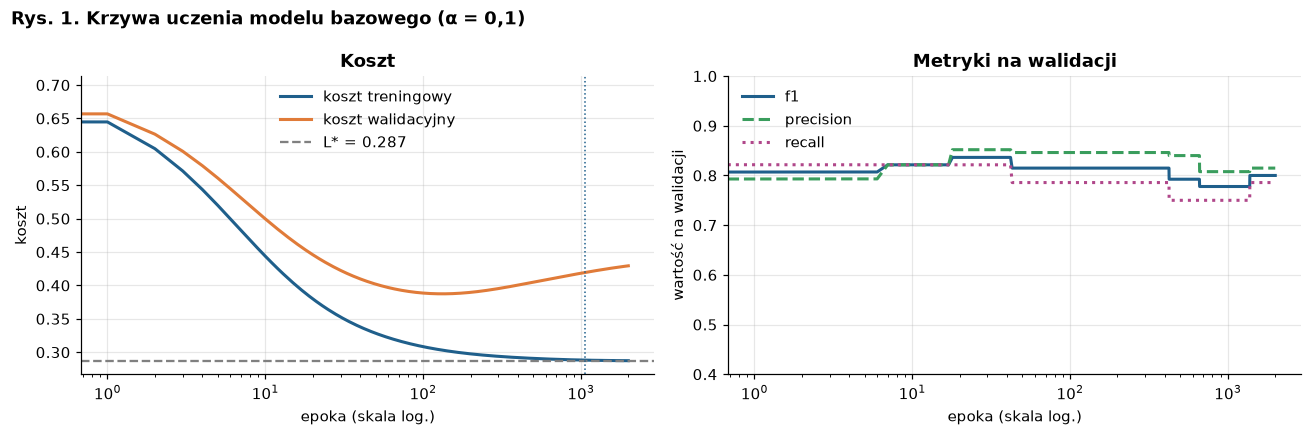

In [7]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(h["loss"], c=C["train"], lw=2, label="koszt treningowy")
ax[0].plot(h["val_loss"], c=C["val"], lw=2, label="koszt walidacyjny")
ax[0].axhline(L_star, ls="--", c=C["ref"], label=f"L* = {L_star:.3f}")
ax[0].axvline(epochs_to(h["loss"], target), ls=":", c=C["train"], lw=1)
ax[0].set(xscale="log", xlabel="epoka (skala log.)", ylabel="koszt", title="Koszt")
ax[0].legend()
for k, ls in [("f1", "-"), ("precision", "--"), ("recall", ":")]:
    ax[1].plot(h["val_" + k], ls, c=C[k], lw=2, label=k)
ax[1].set(xscale="log", ylim=(0.4, 1), xlabel="epoka (skala log.)", ylabel="wartość na walidacji", title="Metryki na walidacji")
ax[1].legend()
rys(fig, 1, "Krzywa uczenia modelu bazowego (α = 0,1)")

**Co widać:**
- koszt treningowy spada od $\ln 2 = 0{,}693$ (wagi zerowe, p = 0,5 dla każdego pacjenta) i po 1067 epokach dochodzi do $L^*$ (kropkowana linia),
- koszt walidacyjny najpierw spada razem z treningowym, potem się wypłaszcza i lekko rośnie: to pierwszy sygnał przeuczenia,
- F1, precision i recall ustalają się na ok. 0,8 już po kilkunastu epokach (F1: 0,63 → 0,82 po 10 epokach) i dalej zmieniają się tylko o 1–2 pacjentów,
- na teście precision = recall = 0,786: 22 chorych wykrytych, 6 fałszywych alarmów, 6 pominiętych.

> **Wniosek:** model zbiega do minimum globalnego, ale decyzje (F1) są gotowe dużo wcześniej niż koszt. Dalszy trening poprawia głównie pewność predykcji.

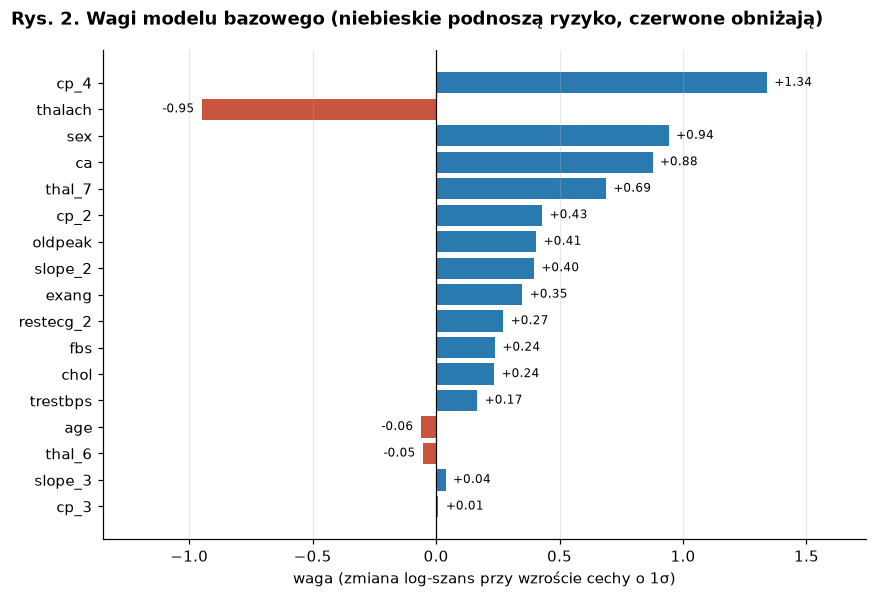

In [8]:
order = np.argsort(np.abs(base.w))
fig, ax = plt.subplots(figsize=(8, 5.5))
vals = base.w[order]
ax.barh([names[i] for i in order], vals, color=[C["neg"] if v < 0 else C["pos"] for v in vals])
for yi, v in enumerate(vals):
    ax.text(v + (0.03 if v >= 0 else -0.03), yi, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, c="k", lw=0.8); ax.grid(axis="y", visible=False)
ax.set(xlabel="waga (zmiana log-szans przy wzroście cechy o 1σ)", xlim=(vals.min() - 0.4, vals.max() + 0.4))
rys(fig, 2, "Wagi modelu bazowego (niebieskie podnoszą ryzyko, czerwone obniżają)")

**Co widać:**
- cechy są standaryzowane, więc długości słupków można porównywać: waga to zmiana log-szans choroby przy wzroście cechy o jedno odchylenie standardowe,
- najsilniej działają **cp_4** (ból bezobjawowy, +1,34), **thalach** (maks. tętno, −0,95), **sex** (+0,94), **ca** (liczba zwężonych naczyń, +0,88) i **thal_7** (defekt odwracalny, +0,69),
- przykład: cp_4 = +1,34 oznacza szanse choroby większe ok. $e^{1{,}34} \approx 3{,}8$ raza.

> **Wniosek:** model jest interpretowalny i wskazuje te same cechy, które w ćw. 1 były najsilniej skorelowane z chorobą.

## 4. Wpływ współczynnika uczenia α

Wagi zerowe, 5000 epok, α od $10^{-4}$ do 100. Status: **zbiega** (doszedł do $L^*$), **za wolno** (koszt nadal maleje, ale nie doszedł) albo **oscyluje** (koszt skacze).

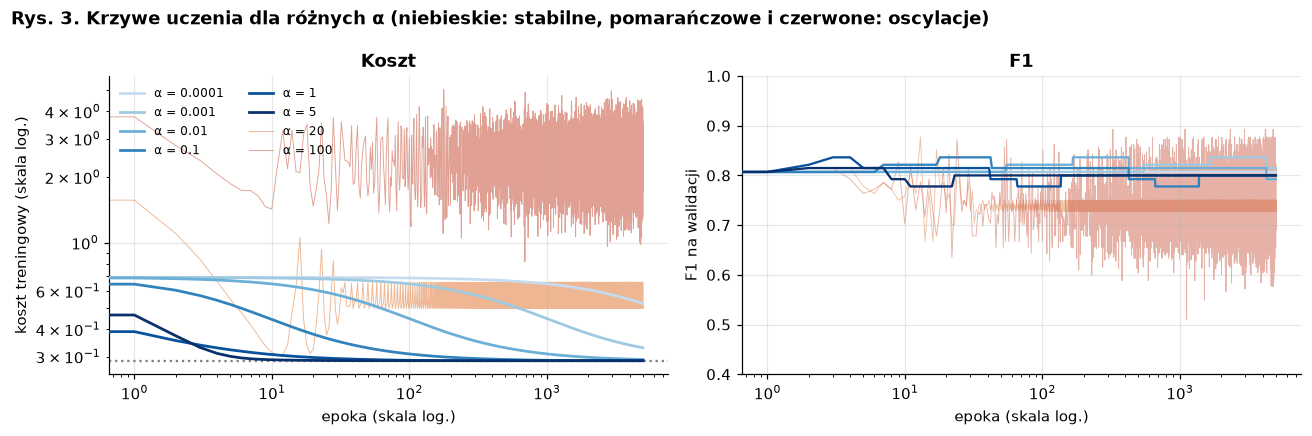

,status,epoki do zbieżności,koszt końcowy,F1 val,F1 test
α,,,,,
0.0001,za wolno,—,0.5247,0.807,0.772
0.0010,za wolno,—,0.3291,0.815,0.772
0.0100,za wolno,—,0.2908,0.792,0.793
0.1000,zbiega,1067,0.2872,0.8,0.772
1.0000,zbiega,106,0.2872,0.8,0.772
5.0000,zbiega,18,0.2872,0.8,0.772
20.0000,oscyluje,—,0.4996,0.727,0.807
100.0000,oscyluje,—,3.5676,0.772,0.828


In [9]:
lrs = [0.0001, 0.001, 0.01, 0.1, 1.0, 5.0, 20.0, 100.0]
cmap = ["#c6dbef", "#9ecae1", "#6baed6", "#3182bd", "#08519c", "#08306b", "#e07b39", "#c8553d"]  # niebieskie: stabilne, pomarańcz/czerwień: za duże α
rows = {}
fig, ax = plt.subplots(1, 2)
for col, lr in zip(cmap, lrs):
    m = LogisticRegressionGD(lr=lr, epochs=5000).fit(Xtr, ytr, Xva, yva)
    L = np.array(m.history["loss"]); ep = epochs_to(L, target)
    status = "zbiega" if ep is not None else ("za wolno" if np.all(np.diff(L[-200:]) <= 0) else "oscyluje")
    rows[lr] = {"status": status, "epoki do zbieżności": ep if ep is not None else "—",
                "koszt końcowy": round(L[-1], 4), "F1 val": round(metrics(yva, m.predict_proba(Xva))["f1"], 3),
                "F1 test": round(metrics(yte, m.predict_proba(Xte))["f1"], 3)}
    osc = status == "oscyluje"
    ax[0].plot(L, c=col, lw=0.6 if osc else 1.8, alpha=0.55 if osc else 1, zorder=1 if osc else 3, label=f"α = {lr:g}")
    ax[1].plot(m.history["val_f1"], c=col, lw=0.6 if osc else 1.5, alpha=0.45 if osc else 1, zorder=1 if osc else 3, label=f"α = {lr:g}")
ax[0].axhline(L_star, ls=":", c=C["ref"], lw=1.5)
ax[0].set(xscale="log", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)", title="Koszt")
ax[1].set(xscale="log", ylim=(0.4, 1), xlabel="epoka (skala log.)", ylabel="F1 na walidacji", title="F1")
ax[0].legend(fontsize=8, ncol=2)
rys(fig, 3, "Krzywe uczenia dla różnych α (niebieskie: stabilne, pomarańczowe i czerwone: oscylacje)")
pd.DataFrame(rows).T.rename_axis("α")

**Co widać:**
- **α ≤ 0,01 – za wolno:** koszt maleje równo, ale po 5000 epokach nadal jest nad $L^*$ (0,52 / 0,33 / 0,29),
- **α = 0,1 / 1 / 5 – zbiega:** ten sam koszt końcowy 0,2872, a liczba epok maleje prawie odwrotnie proporcjonalnie do α: 1067 → 106 → 18,
- **α ≥ 20 – oscyluje:** przy α = 20 koszt do końca skacze między ok. 0,5 a 0,65, a przy α = 100 kończy nawet wyżej niż na starcie (powyżej 0,693), a F1 skacze z epoki na epokę,
- ewentualne wyższe F1 testowe przy dużym α to przypadek: na 61 pacjentach jedna osoba zmienia F1 o ok. 0,02, a koszt pokazuje, że model nie zbiegł.

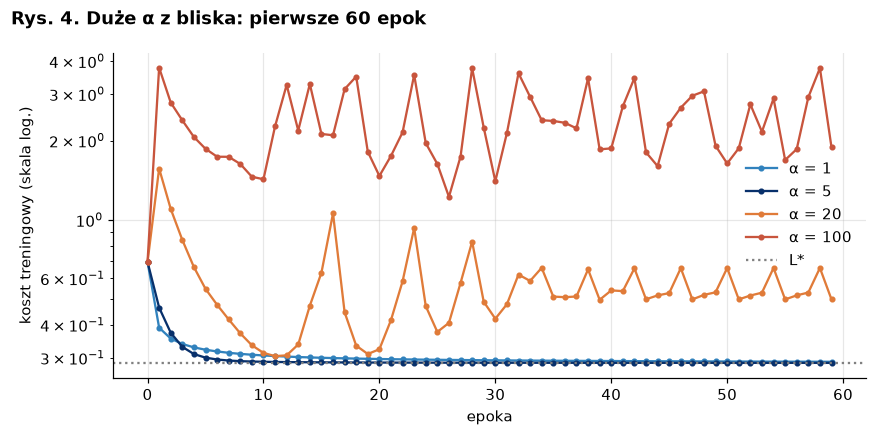

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for col, lr in zip(["#3182bd", "#08306b", "#e07b39", "#c8553d"], [1.0, 5.0, 20.0, 100.0]):
    ax.plot(LogisticRegressionGD(lr=lr, epochs=60).fit(Xtr, ytr).history["loss"], marker=".", c=col, label=f"α = {lr:g}")
ax.axhline(L_star, ls=":", c=C["ref"], label="L*")
ax.set(yscale="log", xlabel="epoka", ylabel="koszt treningowy (skala log.)")
ax.legend()
rys(fig, 4, "Duże α z bliska: pierwsze 60 epok")

**Co widać:** przy α = 5 koszt dochodzi do minimum w kilkanaście epok, przy α = 1 schodzi płynnie, ale wolniej. Przy α = 20 koszt raz prawie dotyka minimum, a raz skacze do ok. 1, i tak w kółko. Przy α = 100 skacze między ok. 1,2 a 3,8, czyli daleko nad startem.

> **Wniosek:** α decyduje o szybkości, ale nie o tym, gdzie trafia model. Wszystkie stabilne α dochodzą do tego samego $L^*$. Zbyt duże α **uniemożliwia** zbieżność, bo krok jest dłuższy niż „dolina” kosztu i przeskakuje jej dno.

## 5. Wpływ inicjalizacji wag

α = 0,1, 5000 epok. Badane rozkłady wag startowych (bias zawsze 0):

| nazwa | znaczenie |
|---|---|
| zera | wszystkie wagi = 0 |
| normal(σ) | losowo z N(0; σ) |
| uniform(a) | losowo z U(−a; a) |
| const(5) | wszystkie wagi = 5 |

Dla rozkładów losowych 10 losowań, pokazuję średnią i zakres. ‖w − w*‖ to odległość końcowych wag od wag w minimum.

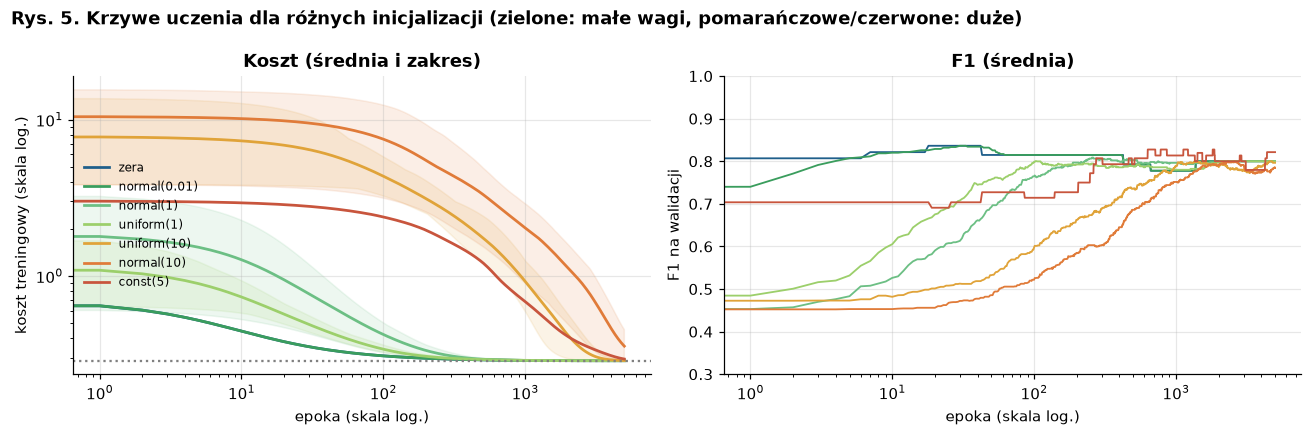

,koszt start,koszt końcowy,epoki do zbieżności,nie zbiegło,F1 test,‖w − w*‖
zera,0.693,0.2872,1067,0/1,0.772,0.013
normal(0.01),0.694,0.2872,1065,0/10,0.772,0.013
normal(1),1.866,0.2872,987,0/10,0.772,0.009
uniform(1),1.15,0.2872,1168,0/10,0.772,0.015
uniform(10),7.812,0.2879,3761,2/10,0.787,0.279
normal(10),10.495,0.3558,—,10/10,0.823,3.965
const(5),3.022,0.2943,—,1/1,0.807,1.347


In [11]:
inits = [("zeros", 0.0), ("normal", 0.01), ("normal", 1.0), ("uniform", 1.0), ("uniform", 10.0), ("normal", 10.0), ("const", 5.0)]
cols = ["#1f5f8b", "#3a9d5d", "#6cbf84", "#9ccf6b", "#e0a339", "#e07b39", "#c8553d"]
rows = {}
fig, ax = plt.subplots(1, 2)
for col, (kind, sc) in zip(cols, inits):
    label = "zera" if kind == "zeros" else f"{kind}({sc:g})"
    runs = [LogisticRegressionGD(lr=0.1, epochs=5000, init=kind, init_scale=sc, seed=s).fit(Xtr, ytr, Xva, yva)
            for s in range(10 if kind in ("normal", "uniform") else 1)]
    L = np.array([r.history["loss"] for r in runs]); conv = [epochs_to(r.history["loss"], target) for r in runs]
    ok = [c for c in conv if c is not None]
    rows[label] = {"koszt start": round(L[:, 0].mean(), 3), "koszt końcowy": round(L[:, -1].mean(), 4),
                   "epoki do zbieżności": round(np.mean(ok)) if ok else "—", "nie zbiegło": f"{len(conv) - len(ok)}/{len(conv)}",
                   "F1 test": round(np.mean([metrics(yte, r.predict_proba(Xte))["f1"] for r in runs]), 3),
                   "‖w − w*‖": round(np.mean([np.linalg.norm(r.w - ref.w) for r in runs]), 3)}
    ax[0].plot(L.mean(0), c=col, lw=1.8, label=label)
    if len(runs) > 1:
        ax[0].fill_between(np.arange(L.shape[1]), L.min(0), L.max(0), color=col, alpha=0.12)
    ax[1].plot(np.mean([r.history["val_f1"] for r in runs], 0), c=col, lw=1.2, label=label)
ax[0].axhline(L_star, ls=":", c=C["ref"], lw=1.5)
ax[0].set(xscale="log", yscale="log", xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)", title="Koszt (średnia i zakres)")
ax[1].set(xscale="log", ylim=(0.3, 1), xlabel="epoka (skala log.)", ylabel="F1 na walidacji", title="F1 (średnia)")
ax[0].legend(fontsize=8)
rys(fig, 5, "Krzywe uczenia dla różnych inicjalizacji (zielone: małe wagi, pomarańczowe/czerwone: duże)")
pd.DataFrame(rows).T

**Co widać:**
- **małe wagi** (zera, normal(0,01), normal(1), uniform(1)) startują z kosztu 0,69–1,9 i wszystkie dochodzą do $L^*$ w ok. 1000 epok; ‖w − w*‖ ≈ 0,01,
- **duże wagi** (uniform(10), normal(10), const(5)) startują z kosztu 3–10; sigmoida jest nasycona (p ≈ 0 lub 1), więc gradient jest mały i koszt przez długi czas spada bardzo wolno,
- po 5000 epokach normal(10) i const(5) nadal nie zbiegły, a uniform(10) potrzebował średnio ok. 3800 epok; F1 po 100 epokach to dla nich tylko 0,52–0,71,
- ‖w − w*‖ dla dużych inicjalizacji (0,3–4) cały czas maleje: model idzie w stronę tego samego minimum,
- wyższe F1 testowe przy normal(10) (0,82) to przypadek modelu, który nie zbiegł: jego koszt (0,356) jest wyraźnie wyższy od $L^*$.

> **Wniosek:** inicjalizacja nie zmienia punktu, do którego zmierza model, bo koszt jest wypukły i nie ma minimów lokalnych. Zła (duża) inicjalizacja tylko **wydłuża** uczenie.

## 6. Liczba epok i warunek stopu

α = 0,1. Porównuję stałą liczbę epok, stop przy $\lvert L_t - L_{t-1}\rvert < \text{tol}$ oraz early stopping: przerwanie, gdy koszt walidacyjny nie spadł przez 50 epok, i powrót do najlepszych wag.

In [12]:
rows = {}
for name, kw in [("stałe 10 epok", dict(epochs=10)), ("stałe 100 epok", dict(epochs=100)),
                 ("stałe 1000 epok", dict(epochs=1000)), ("stałe 20000 epok", dict(epochs=20000)),
                 ("|ΔL| < 1e-4", dict(epochs=20000, stop="tol", tol=1e-4)),
                 ("|ΔL| < 1e-6", dict(epochs=20000, stop="tol", tol=1e-6)),
                 ("early stopping (patience 50)", dict(epochs=20000, stop="early", patience=50))]:
    m = LogisticRegressionGD(lr=0.1, **kw).fit(Xtr, ytr, Xva, yva)
    if kw.get("stop") == "early": es = m
    if kw.get("tol") == 1e-4: t4 = m
    if kw.get("tol") == 1e-6: t6 = m
    rows[name] = {"epoki": int(m.stopped_at), "koszt train": round(bce(ytr, m.predict_proba(Xtr)), 4),
                  "koszt val": round(bce(yva, m.predict_proba(Xva)), 4),
                  "F1 val": round(metrics(yva, m.predict_proba(Xva))["f1"], 3), "F1 test": round(metrics(yte, m.predict_proba(Xte))["f1"], 3)}
print("early stopping – najlepsza epoka:", es.best_epoch)
pd.DataFrame(rows).T

early stopping – najlepsza epoka: 133


,epoki,koszt train,koszt val,F1 val,F1 test
stałe 10 epok,10.0,0.4439,0.4997,0.821,0.772
stałe 100 epok,100.0,0.3084,0.3886,0.815,0.764
stałe 1000 epok,1000.0,0.2883,0.4183,0.778,0.786
stałe 20000 epok,20000.0,0.2872,0.4367,0.800,0.772
|ΔL| < 1e-4,148.0,0.3014,0.3876,0.815,0.786
|ΔL| < 1e-6,1400.0,0.2877,0.4241,0.800,0.786
early stopping (patience 50),183.0,0.3031,0.3874,0.815,0.764


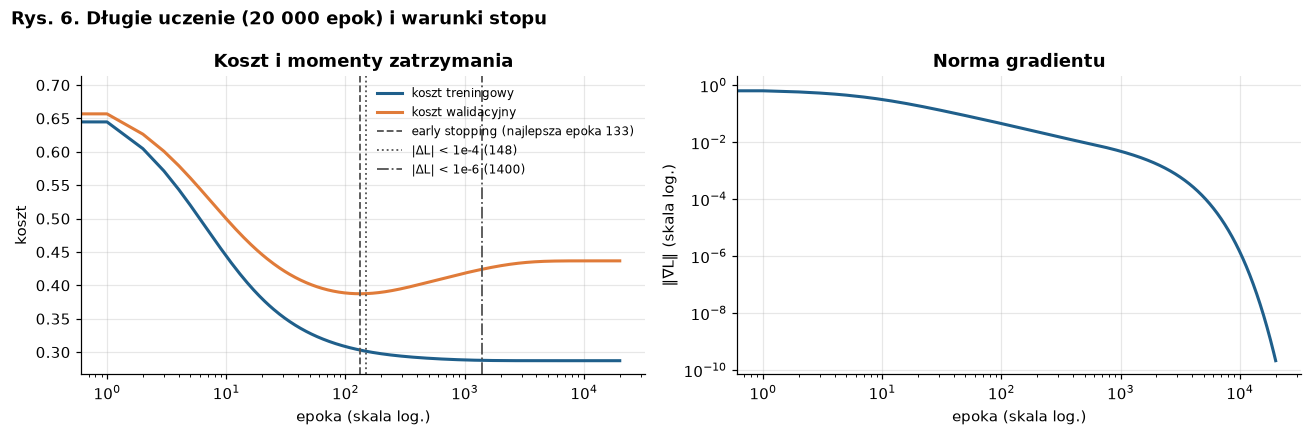

In [13]:
long_m = LogisticRegressionGD(lr=0.1, epochs=20000).fit(Xtr, ytr, Xva, yva)
long = long_m.history
fig, ax = plt.subplots(1, 2)
ax[0].plot(long["loss"], c=C["train"], lw=2, label="koszt treningowy")
ax[0].plot(long["val_loss"], c=C["val"], lw=2, label="koszt walidacyjny")
for x, lab, ls in [(es.best_epoch, f"early stopping (najlepsza epoka {es.best_epoch})", "--"),
                   (t4.stopped_at, f"|ΔL| < 1e-4 ({t4.stopped_at})", ":"), (t6.stopped_at, f"|ΔL| < 1e-6 ({t6.stopped_at})", "-.")]:
    ax[0].axvline(x, c="#555555", ls=ls, lw=1.2, label=lab)
ax[0].set(xscale="log", xlabel="epoka (skala log.)", ylabel="koszt", title="Koszt i momenty zatrzymania")
ax[0].legend(fontsize=8)
ax[1].plot(long["grad_norm"], c=C["train"], lw=2)
ax[1].set(xscale="log", yscale="log", xlabel="epoka (skala log.)", ylabel="‖∇L‖ (skala log.)", title="Norma gradientu")
rys(fig, 6, "Długie uczenie (20 000 epok) i warunki stopu")

**Co widać:**
- koszt treningowy maleje do samego końca (0,444 po 10 epokach → 0,287 po 20 000), a norma gradientu równo spada do ok. $10^{-11}$, czyli uczenie jest stabilne i kończy w minimum,
- koszt walidacyjny ma minimum ok. **133. epoki** (0,387), a po 20 000 epokach rośnie do 0,437: model coraz lepiej dopasowuje się do treningu i jest zbyt pewny na nowych danych,
- F1 testowe zmienia się tylko między 0,76 a 0,79 (1–2 pacjentów), bo zależy wyłącznie od strony progu 0,5,
- $\lvert\Delta L\rvert < 10^{-4}$ (148 epok) i early stopping (183, najlepsze wagi z 133) zatrzymują uczenie tam, gdzie walidacja jest najlepsza, ponad 100 razy szybciej niż 20 000 epok.

> **Wniosek:** najniższy koszt treningowy nie oznacza najlepszego modelu. Rozsądny warunek stopu daje ten sam wynik przy ok. 150 epokach, a dłuższe uczenie tylko przeucza model.

## 7. Zła parametryzacja danych: brak standaryzacji

Ten sam model na surowych cechach (cholesterol ok. 250, oldpeak ok. 1). Minimum jest to samo, bo standaryzacja to tylko przeskalowanie osi, ale zmienia się kształt funkcji kosztu. Mierzy to wskaźnik uwarunkowania macierzy $X^TX$.

wskaźnik uwarunkowania XᵀX: standaryzowane 46, surowe 5.52e+06


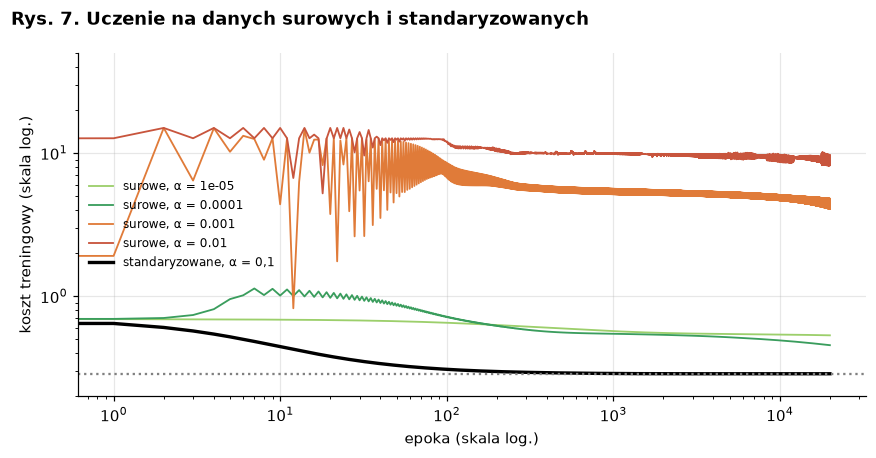

,koszt końcowy,F1 test
"surowe, α = 1e-05",0.5328,0.621
"surowe, α = 0.0001",0.4547,0.667
"surowe, α = 0.001",4.7887,0.691
"surowe, α = 0.01",8.7475,0.683
"standaryzowane, α = 0,1",0.2872,0.772


In [14]:
(Xtr_r, ytr_r), _, (Xte_r, yte_r), _ = load_splits(seed=SEED, standardize=False)
print(f"wskaźnik uwarunkowania XᵀX: standaryzowane {np.linalg.cond(Xtr.T @ Xtr):.0f}, surowe {np.linalg.cond(Xtr_r.T @ Xtr_r):.2e}")
rows = {}
fig, ax = plt.subplots(figsize=(8, 4.2))
for col, lr in zip(["#9ccf6b", "#3a9d5d", "#e07b39", "#c8553d"], [1e-5, 1e-4, 1e-3, 1e-2]):
    m = LogisticRegressionGD(lr=lr, epochs=20000).fit(Xtr_r, ytr_r)
    rows[f"surowe, α = {lr:g}"] = {"koszt końcowy": round(m.history["loss"][-1], 4), "F1 test": round(metrics(yte_r, m.predict_proba(Xte_r))["f1"], 3)}
    ax.plot(m.history["loss"], c=col, lw=1.2, label=f"surowe, α = {lr:g}")
rows["standaryzowane, α = 0,1"] = {"koszt końcowy": round(long["loss"][-1], 4), "F1 test": round(metrics(yte, long_m.predict_proba(Xte))["f1"], 3)}
ax.plot(long["loss"], c="k", lw=2.2, label="standaryzowane, α = 0,1")
ax.axhline(L_star, ls=":", c=C["ref"])
ax.set(xscale="log", yscale="log", ylim=(0.2, 50), xlabel="epoka (skala log.)", ylabel="koszt treningowy (skala log.)")
ax.legend(fontsize=8)
rys(fig, 7, "Uczenie na danych surowych i standaryzowanych")
pd.DataFrame(rows).T

**Co widać:**
- wskaźnik uwarunkowania rośnie z **46 do 5,5 mln**: dolina kosztu jest bardzo wydłużona, stroma w kierunku cholesterolu i prawie płaska w kierunku cech 0/1,
- żadna krzywa dla surowych danych nie zbliża się do czarnej (standaryzowane, $L^* = 0{,}287$): przy α = $10^{-5}$ i $10^{-4}$ koszt po 20 000 epokach to 0,53 i 0,45, a przy α = $10^{-3}$ i $10^{-2}$ koszt skacze i kończy kilka razy wyżej niż na starcie,
- F1 testowe spada z 0,77 do 0,62–0,69.

> **Wniosek:** nie istnieje dobre α. Krok bezpieczny dla stromego kierunku jest za mały dla płaskich, a większy oscyluje. Minimum istnieje, ale brak standaryzacji w praktyce **uniemożliwia** dojście do niego.

## 8. Odpowiedź na pytanie badawcze

| czynnik | wpływ na zbieżność | dowód |
|---|---|---|
| zbyt małe α (≤ 0,01) | **wydłuża** | po 5000 epokach koszt nadal maleje, ale nie doszedł do $L^*$ (Rys. 3) |
| α od 0,1 do 5 | brak problemu | to samo $L^*$ w 1067 / 106 / 18 epok (Rys. 3) |
| zbyt duże α (≥ 20) | **uniemożliwia** | koszt oscyluje, przy α = 100 rośnie ponad start (Rys. 3–4) |
| duża inicjalizacja | **wydłuża** | nasycona sigmoida, ale ‖w − w*‖ maleje (Rys. 5) |
| zbyt długie uczenie | gorsza jakość na nowych danych | koszt walidacyjny rośnie po ok. 133. epoce (Rys. 6) |
| brak standaryzacji | w praktyce **uniemożliwia** | uwarunkowanie 5,5 mln, żadne α nie działa (Rys. 7) |

Klasyfikator liniowy ma jedno minimum globalne, bo funkcja kosztu jest wypukła, i przy poprawnej parametryzacji zawsze do niego dochodzi. Wypukłość nie gwarantuje jednak, że do minimum dojdziemy w praktyce: zbyt duże α i brak standaryzacji to blokują, a mała α i duża inicjalizacja tylko wydłużają uczenie.

## 9. Wnioski

Przy dobrze dobranym α i małych wagach początkowych model zawsze dochodził do tego samego minimum L* = 0,287, co wynika z wypukłości funkcji kosztu. Zbyt małe α i duża inicjalizacja tylko wydłużały uczenie, bo model dalej zmierzał do tego samego punktu, tylko potrzebował tysięcy epok zamiast setek. Zbyt duże α (≥ 20) i brak standaryzacji w praktyce uniemożliwiały zbieżność, bo krok przeskakiwał minimum albo był za mały w części kierunków. Najlepiej sprawdzało się α od 1 do 5, które dochodziło do minimum w kilkadziesiąt do stu epok bez oscylacji. Najniższy koszt treningowy nie oznacza najlepszego modelu: koszt walidacyjny był najmniejszy ok. 133. epoki, więc early stopping lub stop przy |ΔL| < 10⁻⁴ daje ten sam wynik (F1 ≈ 0,79) dużo szybciej.